```{contents}
:local:
:depth: 2
```

# 4.1 Working with Real Data

:::{admonition} Draft status: first draft
:class: warning
First draft (2026-10-30), written from the course design notes. Not yet reviewed.
:::

```{admonition} Lectures
:class: tip
This topic accompanies these recorded lessons:

- Module 9, Lesson 1: *Unstructured Data Challenges*
- Module 9, Lesson 2: *Missing Data Structures*
- Module 9, Lesson 3: *Missing Data Handling Methods*
- Module 9, Lesson 4: *Noise Handling*
- Module 9, Lesson 5: *Outliers*
```

:::{admonition} Learning Objectives
:class: tip

By the end of this topic, you should be able to:

- Explain the difference between designed data and historical (unstructured) data, and what each allows an optimizer to conclude.
- Classify a missing-data pattern as missing completely at random, missing at random, or missing not at random, and explain why the mechanism matters more than the amount.
- Choose between deletion and imputation, and predict how each choice moves the optimum of a model fitted to the data.
- Explain why noise misleads local optimizers and interpolating surrogates, and use regression, replication and the bootstrap to state an optimum with its uncertainty.
- Detect outliers in the output and in the input space, and judge whether to remove them, down-weight them, or model them.
:::

In Topics 3.1–3.6 we treated the electrolyzer as a black box, but it was a very well-behaved black box: we could choose where to sample it, and it would return the exact power at that load. Unfortunately, real plants are not so well-behaved. In practice, most of the data an engineer has access to comes from a "data historian", which is the database that logs every sensor of a running plant, and it simply records whatever the operators happened to do. This means that some readings will be missing, every reading will have some noise, and a few readings will be just plain wrong.

The mechanics of handling this type of data (e.g. finding missing values in pandas, computing z-scores, or imputing with scikit-learn) are covered in DA4CHE Topic 4.1, *Data Organization* (https://www.medford.chbe.gatech.edu/DA4CHE/), so we will only briefly recap them here. In this course we are interested in a narrower question: if we fit a model to imperfect data and then optimize it, how far does the optimum move, and in which direction?

## Designed data and historian data

:::{admonition} Adapted material
:class: note
The framing of this section (designed versus unstructured data, the four V's, and the comparison of the number of samples with the number of dimensions) follows the course notebook `Dealing with bigger and unstructured data.ipynb` (MIT License, © 2022 Data-Driven PSE Lab @ChBE-GT).
:::

So far, all of the data we have worked with has been **designed**. A design of experiments (e.g. the Latin hypercube from Topic 3.5) chooses where to sample so that the samples cover the region we care about. Simulations are the most common example, since we can run them anywhere we want. **Unstructured** (or undesigned) data is everything else, such as historical sensor logs from a running unit, literature results merged from several sources, web data, or even video from a process camera. The key difference is that with unstructured data we cannot go back and put a sample where we would like one.

Data sets like this are often described as "big data", although the term means different things in different fields. For a computer scientist it typically means terabytes of data and millions of dimensions, but for a chemical engineer it often just means a spreadsheet with a few thousand rows and a few dozen columns that is too complex to handle with standard techniques. The character of these data sets is usually summarized by the "four V's":

- **Volume**: many samples or many dimensions. For data-driven optimization, about 20 variables is already high-dimensional (for machine learning, about 100).
- **Variety**: continuous, integer and categorical variables, or arrays (time series, spectra, images) alongside scalars. Variety needs specialized preprocessing, often leads to high dimensionality, and makes the optimization mixed-integer.
- **Velocity**: data arriving fast enough to need online decisions, such as a reactor controller re-solving an optimization every second when a composition drifts out of bounds. If no online decision is needed, velocity becomes a volume problem.
- **Veracity**: noise, outliers and missing values, the subject of this topic. Little noise with enough data can be handled by regression and regularization; heavy noise, scarce data or many outliers call for preprocessing before any regression or optimization.

There are two numbers that frame every data set: the number of samples, $N$, and the number of dimensions, $d$. If $N \gg d$ then there is usually enough information to learn an input-output map, although interpolating surrogates such as Gaussian processes will become slow to train and large to optimize. If $N \ll d$ then we cannot safely learn the map, and no model may have more parameters than there are data points. However, we can still screen for correlations and look for the true dimensionality of the data, which is the subject of {doc}`Topic4.2-Optimization_in_Reduced_Spaces`.

In this topic we will work with a synthetic historian log from stack A, which was run for 400 hours at loads that the operators chose. The log records the load setpoint, three flow meters (hydrogen, feed water and oxygen), the stack temperature, and the stack power. We know that the true power curve is the S-curve introduced in Topic 1.1, so we can measure how far each data-driven answer is from the truth. The quantity we want to optimize is the **specific energy**, which is the power drawn per unit of hydrogen made, $P(x)/x$. The minimum of the specific energy is the stack's **best-efficiency load**.

findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


historian log: N = 400 records, d = 6 columns
   load  h2_kg_h  water_kg_h  o2_kg_h  temp_C  power_MW
0  0.50    98.66      898.74   789.58   62.79      5.89
1  0.33    66.20      585.92   518.78   59.08      4.21
2  0.56   111.43     1001.38   885.35   64.05      6.52
true best-efficiency load x* = 0.725 (145 kg/h), specific energy 1.7496 per-unit = 57.2 kWh/kg
fraction of logged hours above 85% load: 0.075


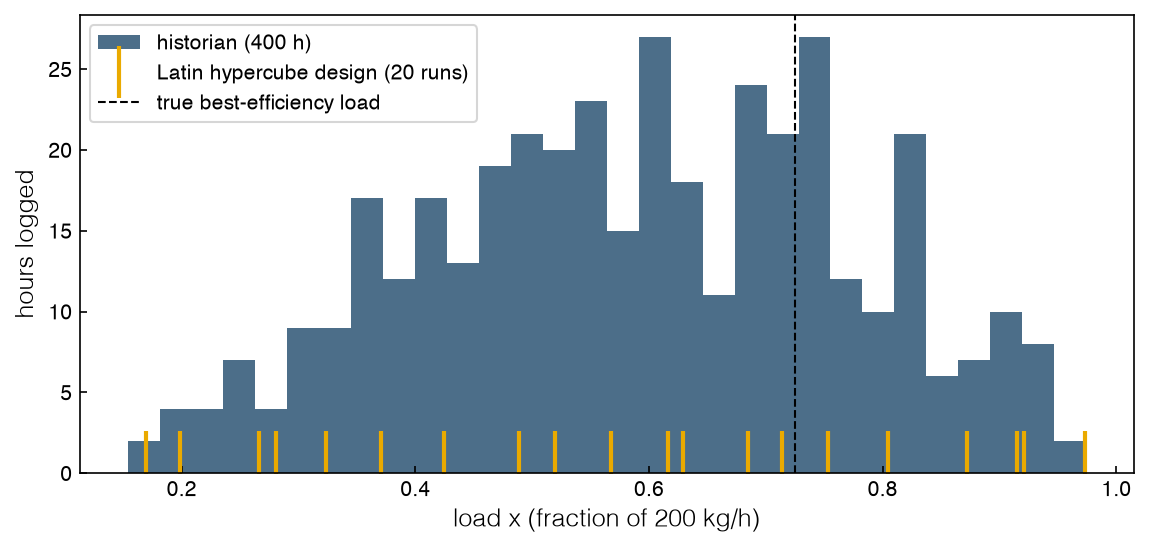

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use('../settings/plot_style.mplstyle')
from scipy.stats import qmc
from _lib import electrolyzer as el
from _lib import part4a_tools as t4

log = t4.stack_log()                 # 400 hourly records of stack A, seed 0
N, d = log.shape
print(f"historian log: N = {N} records, d = {d} columns")
print(log.head(3).round(2).to_string())

k = t4.KWH_PER_KG_PER_UNIT           # per-unit specific energy -> kWh/kg
xg = np.linspace(0.05, 1, 20001)
X_STAR = xg[t4.specific_energy(xg).argmin()]
SE_STAR = float(t4.specific_energy(X_STAR))
print(f"true best-efficiency load x* = {X_STAR:.3f} ({el.to_kg_h(X_STAR):.0f} kg/h), "
      f"specific energy {SE_STAR:.4f} per-unit = {SE_STAR * k:.1f} kWh/kg")
print(f"fraction of logged hours above 85% load: {(log.load > 0.85).mean():.3f}")

lhs = 0.15 + 0.85 * qmc.LatinHypercube(d=1, seed=0).random(20).ravel()
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(log.load, bins=30, alpha=0.7, label='historian (400 h)')
ax.plot(lhs, np.full_like(lhs, 1.0), '|', ms=25, mew=2, label='Latin hypercube design (20 runs)')
ax.axvline(X_STAR, color='k', ls='--', lw=1, label='true best-efficiency load')
ax.set_xlabel('load $x$ (fraction of 200 kg/h)')
ax.set_ylabel('hours logged')
ax.legend(fontsize=10);

We can see that the best-efficiency load of stack A is $x^* = 0.725$ (about 145 kg/h), where the stack uses 1.7496 times the ideal energy, or 57.2 kWh per kilogram of hydrogen. The histogram shows that the operators spent most of their time at middling loads and only 7.5% of the hours above 85% load, which means that the historian says much more about some loads than about others, unlike the 20-run design.

Before we can optimize anything we need a model. The power is close to a quadratic in load, $\hat P(x) = b_0 + b_1 x + b_2 x^2$, where $b_0$ stands in for the losses that do not scale with load and $b_2$ stands in for the resistive losses. If we divide this by $x$ we get the specific energy, $\hat P(x)/x = b_0/x + b_1 + b_2 x$, which has a minimum at $\hat x^* = \sqrt{b_0/b_2}$ as long as both coefficients are positive. This is a regression surrogate in the same sense as Topic 3.5, since it is fitted to the measured power and then used to optimize the derived specific energy, and we only optimize over the range of loads in the data because the model has no support outside of that range.

In [2]:
def best_load(x, p_mw, lo=None, hi=None):
    """Fit P(x) = b0 + b1 x + b2 x^2 to (load, measured power); minimize P/x over the data's load range."""
    x = np.asarray(x, float)
    b2, b1, b0 = np.polyfit(x, np.asarray(p_mw) / el.MW_PER_UNIT, 2)
    g = np.linspace(x.min() if lo is None else lo, x.max() if hi is None else hi, 2001)
    se = b0 / g + b1 + b2 * g
    return float(g[se.argmin()]), float(se.min())

xh, se_hat = best_load(log.load, log.power_MW)
print(f"complete log: estimated x* = {xh:.3f}, predicted SE = {se_hat:.4f}, "
      f"true SE there = {t4.specific_energy(xh):.4f}")

complete log: estimated x* = 0.721, predicted SE = 1.7509, true SE there = 1.7496


If we use the complete log, the surrogate puts the best-efficiency load at 0.721 and predicts a specific energy of 1.7509, and the true value at that load is 1.7496, which is the same as the true optimum to four digits. We will use this as our reference answer, and in each of the sections below we will damage the log in one way and then ask how much of this answer survives.

:::{exercise}
:label: ex-t41-design-vs-log

Fit `best_load` to the 20-run Latin hypercube instead of the historian: evaluate the true power `el.to_mw(el.p_scurve(lhs, 'A'))` at the design points, add 1% multiplicative noise with a fixed seed, and compare the estimated best-efficiency load with the 400-hour historian result. Then keep only the historian records with load below 0.6 and repeat. Which data set gives the better answer, and why?
:::

## How data goes missing

Data can go missing for many reasons, including sensor failures, experiments that were never performed, outliers that were removed, or data sets that were merged from sources that did not follow the same plan. Missing values differ both in how many are missing (e.g. 1% or 80%) and in why they are missing, and it turns out that the second one matters more, since a large amount of data that is missing not at random can make a data set dangerous to use at all. In statistics we usually distinguish three **mechanisms**:

- **Missing completely at random (MCAR).** Whether a value is missing has nothing to do with any value in the data set, observed or not. A logger that drops a random record now and then is MCAR; a sensor that always fails in one reactor because its conditions are extreme is not. No bias is introduced, so even a fairly large fraction of MCAR values can be tolerated.
- **Missing at random (MAR).** Missingness depends on other variables that we do observe, but not on the missing value itself. In the lectures the example is a survey in which one group responds less often than another for reasons unrelated to the answer. In a plant, a power reading might drop out more often during cold periods because the logging computer is busy with start-up sequences; the temperature is in the log, so the cause is visible.
- **Missing not at random (MNAR).** The probability that a value is missing depends on the value itself. The standard engineering case is a sensor with a limited range: a composition below the detection limit, or a power meter that saturates and logs nothing above its range. MNAR is the dangerous one, because the missing values are systematically different from the observed ones.

In engineering, missing data tend to be either completely random or not random at all, and MNAR mechanisms (or merged sources) will often leave whole blocks, rows or columns of the data empty. Different machine-learning tools also tolerate these gaps differently. There are formal statistical tests for the mechanism, but these are beyond the scope of this course, so in practice the best tool is to look at the data by plotting a heat map of the missing-value pattern, with the records sorted by something that might explain it.

To see what the three mechanisms look like, we will damage the power column of the historian in three different ways, and in all three cases we also blank out 5% of the other four sensor readings at random. The MCAR case drops 20% of the power readings at random, the MAR case drops power readings with probability 0.6 when the stack temperature is below 60 °C (and 0.05 otherwise), and the MNAR case models a meter that logs nothing above 8 MW.

findfont: Failed to find font weight ultralight for Helvetica, now using 300.


MCAR  missing 0.220; highest load with power observed 0.947
MAR   missing 0.165; highest load with power observed 0.936
MNAR  missing 0.302; highest load with power observed 0.707


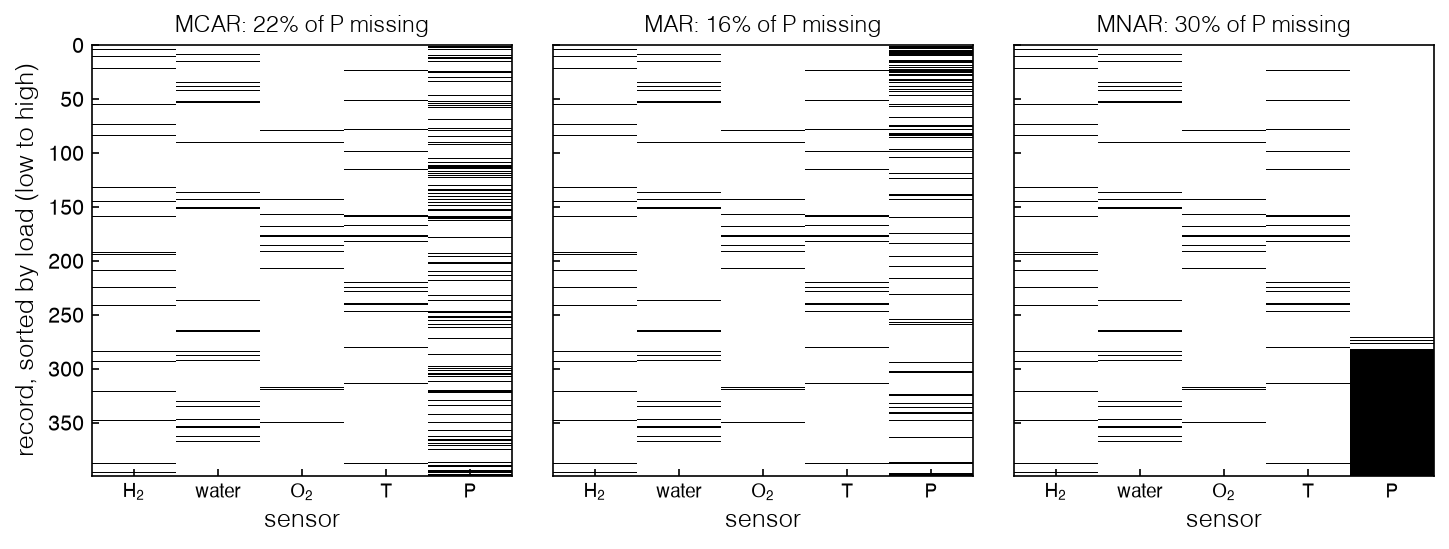

In [3]:
rng = np.random.default_rng(42)
n = len(log)
masks = {
    'MCAR': rng.random(n) < 0.20,                                   # random logger dropouts
    'MAR': rng.random(n) < np.where(log.temp_C < 60, 0.60, 0.05),   # depends on observed temperature
    'MNAR': (log.power_MW > 8.0).values,                            # meter over-range above 8 MW
}
sensor_gaps = rng.random((n, 4)) < 0.05                             # 5% MCAR gaps in the other sensors
cols = ['h2_kg_h', 'water_kg_h', 'o2_kg_h', 'temp_C', 'power_MW']

order = np.argsort(log.load.values)
fig, axes = plt.subplots(1, 3, figsize=(10, 4), sharey=True)
for ax, (name, m) in zip(axes, masks.items()):
    miss = np.column_stack([sensor_gaps, m])[order]
    ax.imshow(miss, aspect='auto', cmap='Greys', interpolation='nearest')
    ax.set_xticks(range(5))
    ax.set_xticklabels(['H$_2$', 'water', 'O$_2$', 'T', 'P'], fontsize=9)
    ax.set_title(f"{name}: {m.mean():.0%} of P missing", fontsize=11)
    ax.set_xlabel('sensor')
axes[0].set_ylabel('record, sorted by load (low to high)')
for name, m in masks.items():
    print(f"{name:5s} missing {m.mean():.3f}; highest load with power observed {log.load[~m].max():.3f}")

In these plots the black marks are the missing values. The MCAR power column is speckled evenly, while the MAR column is speckled more heavily at the top, among the low-load records, since a cold stack is usually a lightly loaded one. The MNAR column is a solid block, and the highest load with a power reading is 0.707, which is just below the true best-efficiency load of 0.725. This means that the data we would need to locate the optimum are exactly the data that are missing.

:::{exercise}
:label: ex-t41-mechanism

Make a fourth mask in which the power meter fails for whole days: split the 400 records into 16 consecutive blocks of 25 and blank the power column in 4 randomly chosen blocks. Plot its pattern twice, once in record order and once sorted by load. Which mechanism is it, and which of the two plots shows that?
:::

## Handling missing data

:::{admonition} Adapted material
:class: note
The comparison of deletion with imputation follows the course notebook `Outliers and Missing Values.ipynb` (MIT License, © 2022 Data-Driven PSE Lab @ChBE-GT), which used a scikit-learn example on a public data set. Here the comparison is rebuilt on the electrolyzer historian, with current scikit-learn imputers.
:::

The best remedy for missing data is to not have any in the first place, which means using good sensors and redundant measurements. If that is not possible, we can either delete the incomplete records or impute the missing values. The pandas and scikit-learn mechanics for doing this are covered in DA4CHE Topic 4.1, and the main options are summarized below.

- **Deletion.** Remove rows (or columns) with missing values; drop a row if most of it is missing, a column if most of it is missing. The observed values in those rows are lost too.
- **Mean substitution.** Fill a gap with the column mean, the most probable value if the column is normal. It adds no information, shrinks the column's variance, breaks its correlation with everything else, and biases the data when many values are missing.
- **Regression imputation.** Predict the incomplete column from the complete ones with a surrogate. It adds no information either, but it preserves correlations, the spread of the column and the shape of its distribution; scikit-learn's `IterativeImputer` cycles column by column until the filled values settle.
- **Nearest-neighbor imputation.** Copy the value of the most similar complete record (or average the $k$ most similar). No model is fitted, but all pairwise distances must be computed.
- **Maximum likelihood and expectation-maximization (EM).** Assume the rows come from a distribution, say a multivariate normal with mean $\mu$ and covariance $\Sigma$, and choose $(\mu, \Sigma)$ to maximize the likelihood, the measure of fit between data and model (for linear regression with normal errors, maximizing it is minimizing the sum of squared errors). The E-step fills each gap with its expected value given its row's observed values and the current $(\mu, \Sigma)$; the M-step re-estimates $(\mu, \Sigma)$; the two repeat to convergence. EM is often combined with the dimensionality reduction of Topic 4.2.
- **Last observation carried forward.** For time series, repeat the last reading. It fails exactly when the gap was caused by an unusual event.

There are a few rules of thumb that can help with this choice. A row or column that is mostly missing should be removed, and for a small amount (under about 10%) that is missing at random, mean substitution may be good enough. For larger amounts, regression imputation or EM is usually the better choice, and methods can be combined as needed. For randomly missing values, a surrogate that is fitted to the completed data set will usually be more accurate than one that is fitted after deleting rows.

For optimization, what we really care about is where the optimum of the resulting model lands, which is related to how accurate the imputed values are but is not the same thing. The next cell applies each method to each mechanism, refits the power surrogate, and then reports the imputation error, the estimated best-efficiency load, and the true specific energy at that load.

In [4]:
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import StandardScaler

def impute(df, method):
    """Fill the gaps in the five sensor columns; the load setpoint is always known."""
    Z = df[cols].values
    if method == 'mean':
        return SimpleImputer(strategy='mean').fit_transform(Z)
    sc = StandardScaler().fit(Z)                     # scaler ignores NaNs when fitting
    imp = KNNImputer(n_neighbors=5) if method == 'kNN' else IterativeImputer(random_state=0, max_iter=20)
    return sc.inverse_transform(imp.fit_transform(sc.transform(Z)))

rows = []
for name, m in masks.items():
    dmg = log.copy()
    dmg.loc[m, 'power_MW'] = np.nan
    dmg.loc[:, cols[:4]] = dmg[cols[:4]].mask(sensor_gaps)
    xs, _ = best_load(dmg.load[~m], dmg.power_MW[~m])
    rows.append((name, 'delete rows', np.nan, xs, t4.specific_energy(xs) * k))
    for method in ['mean', 'kNN', 'regression']:
        P = impute(dmg, method)[:, 4]
        rmse = np.sqrt(np.mean((P[m] - log.power_MW.values[m]) ** 2))
        xs, _ = best_load(dmg.load, P)
        rows.append((name, method, rmse, xs, t4.specific_energy(xs) * k))
tab = pd.DataFrame(rows, columns=['mechanism', 'method', 'imputation RMSE (MW)',
                                  'estimated x*', 'true SE at x* (kWh/kg)'])
print(tab.round(3).to_string(index=False))
print(f"true optimum: x* = {X_STAR:.3f}, SE = {SE_STAR * k:.2f} kWh/kg")

mechanism      method  imputation RMSE (MW)  estimated x*  true SE at x* (kWh/kg)
     MCAR delete rows                   NaN         0.721                  57.169
     MCAR        mean                 2.132         0.974                  58.161
     MCAR         kNN                 0.161         0.744                  57.177
     MCAR  regression                 0.155         0.791                  57.253
      MAR delete rows                   NaN         0.717                  57.170
      MAR        mean                 2.659         0.770                  57.210
      MAR         kNN                 0.174         0.730                  57.169
      MAR  regression                 0.173         0.774                  57.217
     MNAR delete rows                   NaN         0.707                  57.175
     MNAR        mean                 3.426         0.974                  58.161
     MNAR         kNN                 1.517         0.974                  58.161
     MNAR  regre

The table is easiest to read if we go through it one mechanism at a time.

**MCAR.** Deletion is harmless here, since 78% of a random sample is still a random sample, and the optimum stays at 0.721. Mean substitution writes the average power (about 6.9 MW) into rows at every load, which flattens the fitted curve and pushes the optimum to the edge of the data at 0.974. Nearest-neighbor and regression imputation recover the missing readings to within about 0.16 MW, because the flow meters track the load closely, and they give optima of 0.744 and 0.791.

**MAR.** The pattern for data that are missing at random is similar. Deletion is still nearly unbiased and gives an optimum of 0.717. This is because the cause of the gaps is the temperature, which is a function of load, and the surrogate is also a function of load, so conditioning on load removes the bias. Mean substitution again has by far the largest imputation error at 2.66 MW, although this time its optimum of 0.770 happens to land close to the one we get from regression imputation, which is 0.774.

**MNAR.** If the data are missing not at random, then every method gives a poor answer. Deletion is the least bad, since the surrogate is only fitted up to a load of 0.707 and its minimum lands on that edge, which happens to be close to the true optimum. All three of the imputation methods put the optimum at 0.974. Nearest neighbors can only copy the powers that were observed, and all of these are below 8 MW, so it looks like high load is efficient. Regression imputation does a better job on the missing values, with an RMSE of 0.34 MW, but the linear model that is behind `IterativeImputer` cannot extrapolate the curvature of the power curve, so it makes an error in the same direction. In general, there is no imputation method that can recover information that the mechanism removed systematically. All it can do is extrapolate, and then the optimizer will take advantage of that extrapolation.

From a thermodynamic point of view, the specific-energy curve is flat near its minimum, so even the worst answer in the table (0.974) costs 58.16 kWh/kg instead of 57.17 kWh/kg, which is a penalty of 1.7%.

From an economic point of view, electricity is most of the cost of electrolytic hydrogen, so a 1.7% energy penalty is roughly a 1.7% increase in the dominant operating cost of the stack, and we will pay it for as long as the stack runs at the wrong load.

:::{exercise}
:label: ex-t41-imputation

Replace the linear `IterativeImputer` with one whose estimator can represent curvature: `IterativeImputer(estimator=make_pipeline(PolynomialFeatures(2), Ridge(alpha=1.0)), random_state=0, max_iter=20)`, with `PolynomialFeatures` from `sklearn.preprocessing` and `Ridge` from `sklearn.linear_model`. (The small ridge penalty matters: with plain `LinearRegression` the round-robin iterations diverge on these correlated sensors.) Rerun the MNAR row of the table. Does the estimated optimum improve, and how far above 8 MW do the imputed powers now reach? What does this say about when model-based imputation can and cannot fix MNAR data?
:::

## Noise and the optimizer

Real process data is never free of noise, since human error, sensor calibration and resolution, and the environment all contribute to it. **Noise** is measurement error, and it is usually modeled as $y = f(x) + \varepsilon$ with $\varepsilon \sim \mathcal{N}(0, \sigma^2)$. An **outlier** is a value that is very different from the rest, which might be a very large error or might be the system genuinely behaving differently (we will discuss this in the next section). The **signal-to-noise ratio** compares the variance of the signal with the variance of the noise. When it is high, the directions of large variance in the data are real correlations and the directions of small variance are noise, which is the idea behind PCA in Topic 4.2. When it is low, the noise makes prediction impossible, or the "noise" is actually real variation that we have not explained yet. In our historian, the power meter has a 1% relative error on every reading.

Optimizers react to differences, and near an optimum the differences are small. Let's see what happens if we use Nelder-Mead (Topic 3.2) to read the meter directly, starting from ten different loads, where each evaluation is a fresh reading with 1% noise.

In [5]:
from scipy.optimize import minimize

def measured_se(x, rng, sig):
    """One reading of specific energy at load x, with relative meter noise sig."""
    x = float(np.clip(np.atleast_1d(x)[0], 0.15, 1.0))
    return float(t4.specific_energy(x) * (1 + sig * rng.standard_normal()))

starts = np.linspace(0.3, 0.95, 10)
for label, sig in [('noise-free', 0.0), ('1% meter noise', 0.01)]:
    finals = []
    for j, x0 in enumerate(starts):
        r = minimize(measured_se, [x0], args=(np.random.default_rng(j), sig), method='Nelder-Mead',
                     options={'xatol': 1e-3, 'fatol': 1e-4})
        finals.append(float(np.clip(r.x[0], 0.15, 1.0)))
    se_f = t4.specific_energy(np.array(finals)) * k
    print(f"{label:15s}: final loads {min(finals):.3f}-{max(finals):.3f}; "
          f"true SE {se_f.min():.2f}-{se_f.max():.2f} kWh/kg")

band = t4.specific_energy(np.linspace(0.55, 0.95, 200))
print(f"SE varies by {band.max() - band.min():.4f} over loads 0.55-0.95; "
      f"one reading has noise sd {0.01 * SE_STAR:.4f}")

noise-free     : final loads 0.724-0.725; true SE 57.17-57.17 kWh/kg
1% meter noise : final loads 0.428-0.908; true SE 57.19-60.18 kWh/kg
SE varies by 0.0254 over loads 0.55-0.95; one reading has noise sd 0.0175


Without noise, all ten runs converge to either 0.724 or 0.725. With 1% noise, the runs stop anywhere between 0.428 and 0.908, and the worst of them runs the stack at 60.18 kWh/kg instead of the optimal value of 57.17 kWh/kg. The last printed line tells us why this happens. From a load of 0.55 to 0.95 the true specific energy only changes by 0.0254 per-unit, while a single reading has a standard deviation of 0.0175. This means that any method that compares individual readings is mostly just comparing the noise, so the method will stop at whichever reading happened to be low. Methods that estimate derivatives with finite differences do even worse, since taking differences amplifies the noise.

The remedy that is emphasized in the lectures is **filtering by regression**. A smooth surrogate with fewer parameters than data points cannot follow every reading, so the noise is averaged away and the optimum of the surrogate lands near the true one. In contrast, an **interpolating** surrogate (e.g. a cubic spline, or a Gaussian process with no noise term) passes through every data point, which means that the noise is reproduced exactly and the minimum lands on whichever reading happened to be low. The next cell compares these two approaches using single readings at 12 evenly spaced loads.

interpolating spline : x* = 0.638, true SE there = 57.34 kWh/kg
quadratic regression : x* = 0.692, true SE there = 57.19 kWh/kg


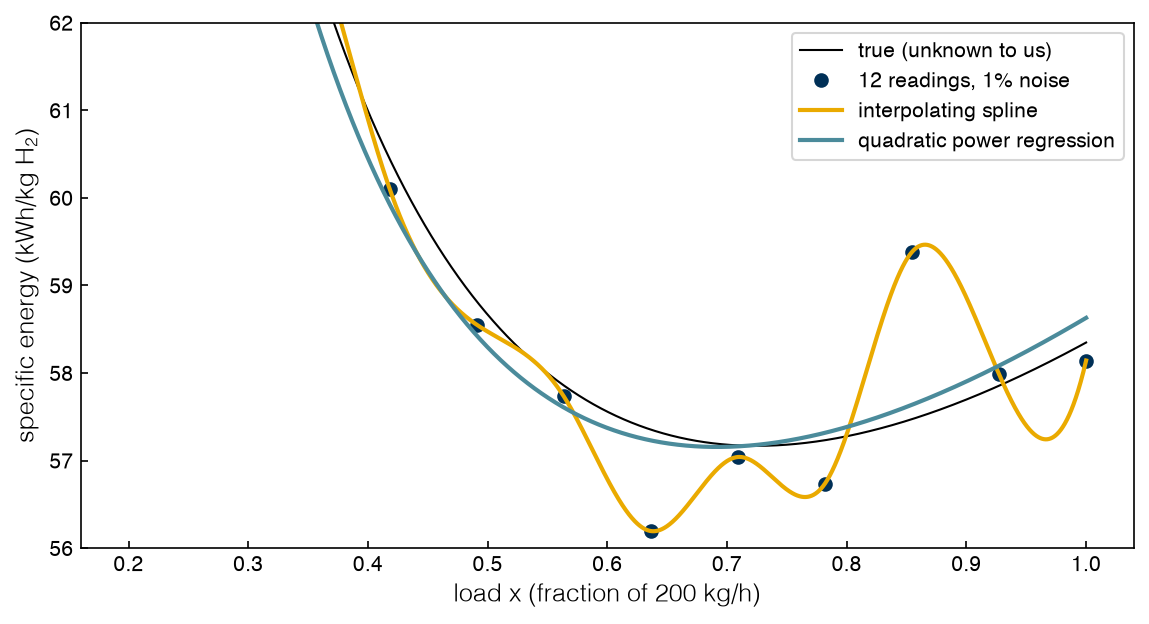

In [6]:
from scipy.interpolate import CubicSpline

rng = np.random.default_rng(3)
xd = np.linspace(0.2, 1.0, 12)
pd_mw = el.to_mw(el.p_scurve(xd, 'A')) * (1 + 0.01 * rng.standard_normal(xd.size))
se_d = pd_mw / el.MW_PER_UNIT / xd
grid = np.linspace(0.2, 1.0, 4001)
spline = CubicSpline(xd, se_d)
x_int = grid[spline(grid).argmin()]
x_reg, _ = best_load(xd, pd_mw)
for lab, xv in [('interpolating spline', x_int), ('quadratic regression', x_reg)]:
    print(f"{lab:21s}: x* = {xv:.3f}, true SE there = {t4.specific_energy(xv) * k:.2f} kWh/kg")

b2, b1, b0 = np.polyfit(xd, pd_mw / el.MW_PER_UNIT, 2)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(grid, t4.specific_energy(grid) * k, 'k-', lw=1, label='true (unknown to us)')
ax.plot(xd, se_d * k, 'o', label='12 readings, 1% noise')
ax.plot(grid, spline(grid) * k, label='interpolating spline')
ax.plot(grid, (b0 / grid + b1 + b2 * grid) * k, label='quadratic power regression')
ax.set_xlabel('load $x$ (fraction of 200 kg/h)')
ax.set_ylabel('specific energy (kWh/kg H$_2$)')
ax.set_ylim(56, 62)
ax.legend(fontsize=10);

The spline puts the optimum at 0.638, where the true cost is 57.34 kWh/kg, and the regression puts it at 0.692, where the true cost is 57.19 kWh/kg. Neither one is exact with only 12 readings, but the error in the regression model is about what we would expect from the noise, while the error in the spline is the noise itself. In general, we should use a regression surrogate rather than an interpolating one whenever the data are noisy, and for a Gaussian process this means that we need to fit a noise (or "nugget") term.

There are two more tools from the lectures that are useful here. The first is the choice of the fitting objective, since least squares is the maximum-likelihood fit for normal errors, while a sum of absolute errors (or the Huber loss that we will use in the next section) is less sensitive to errors with heavy tails. The second is **replication**, which means that we measure several times at the same conditions so that we can estimate the noise and report the optimum with error bars. A historian rarely has exact replicates, but we can get similar information from the **bootstrap**, where we resample the records with replacement many times, refit and re-optimize each time, and then look at the spread of the answers.

In [7]:
rng = np.random.default_rng(7)
B = 1000
boot = np.empty((B, 2))
for b in range(B):
    idx = rng.integers(0, N, N)
    boot[b] = best_load(log.load.values[idx], log.power_MW.values[idx])
lo, hi = np.percentile(boot[:, 0], [5, 95])
slo, shi = np.percentile(boot[:, 1] * k, [5, 95])
print(f"bootstrap 90% interval: x* in [{lo:.3f}, {hi:.3f}] "
      f"({el.to_kg_h(lo):.0f}-{el.to_kg_h(hi):.0f} kg/h); predicted SE in [{slo:.2f}, {shi:.2f}] kWh/kg")

bootstrap 90% interval: x* in [0.709, 0.732] (142-146 kg/h); predicted SE in [57.15, 57.27] kWh/kg


With 400 hours of data, the 90% bootstrap interval for the best-efficiency load is 0.709 to 0.732 (142 to 146 kg/h), and the interval for the predicted specific energy is 57.15 to 57.27 kWh/kg. In general, a data-driven optimum should always be reported in this way, as an interval.

It is also important to remember that noise is only one type of uncertainty. Simulations carry numerical noise (e.g. from solver tolerances, automatic differentiation and finite precision), there is uncertainty in the parameters of the simulation, and the form and fitted parameters of the surrogate add even more uncertainty to the problem. The lectures illustrate the last point with a carbon-sequestration simulation (Espinet and Shoemaker, 2013), where different surrogates that are fitted to the same few samples give different answers. We call uncertainty that would be reduced with more data **epistemic** uncertainty, and we call true randomness **aleatoric** uncertainty. Optimizing an expected or worst-case objective under uncertainty is the subject of the bonus topics on uncertainty ({doc}`../5-uncertainty/Topic5.1-Stochastic_Programming`).

:::{exercise}
:label: ex-t41-noise-floor

Rerun the bootstrap with only the first 50 records of the log, and again with a power meter that has 3% noise (`t4.stack_log(noise=0.03)`). How does the width of the interval on $x^*$ scale with the number of records and with the noise level? Compare the interval on the load with the interval on the specific energy, and explain why one is much wider than the other in relative terms.
:::

## Outliers

:::{admonition} Adapted material
:class: note
The distinction between output outliers and input-output outliers, the use of the Mahalanobis distance, and the rules for handling outliers follow the course notebook `Outliers and Missing Values.ipynb` (MIT License, © 2022 Data-Driven PSE Lab @ChBE-GT). The electrolyzer example replaces the notebook's synthetic sine-wave data.
:::

An **outlier** is an observation that is far from the main population, i.e. one that does not seem to belong to the same distribution as the rest of the data. A record can be an outlier in the output, in the inputs, or in both. If only the output is far off, then a measurement error is the likely cause (although we need enough data to be sure), but if the inputs and the output are both unusual then the record may be correct and describe a different regime of operation.

To study both cases, we will add two kinds of outliers to the historian. First, twelve high-load power readings are spiked by +25%, as if the meter glitched at high current. These are output-only outliers. Second, fifteen records come from cold restarts, with high load, a stack temperature of 53 to 58 °C, and 12% more power, since a cold stack has higher resistive losses. These records are correct, but they describe a different operating regime.

Detection by inspection (i.e. plotting the outputs and discarding whatever looks far away) is still common, but it can be dangerous if it ignores where each point sits in the input space. The simplest statistical test flags values that are more than two or three standard deviations from the column mean (this is the z-score test from DA4CHE Topic 4.1). The course notebook shows that this rule finds outliers easily among 1,000 points, but hardly at all among 50. A better test for the inputs is the **Mahalanobis distance**, which measures how far a point $y$ is from the center $\mu$ of the data in units of the data's own covariance $S$:

$$
D_M^2(y) = (y - \mu)^\top S^{-1} (y - \mu).
$$

Unlike the Euclidean distance, the Mahalanobis distance accounts for correlations, which means that a point can be within the range of every individual variable and still be far from the data if its combination of values is unusual. For normally distributed data in $p$ dimensions, $D_M^2$ follows a $\chi^2$ distribution with $p$ degrees of freedom, and this gives us a threshold. For the outputs, the natural test is on the residuals of a fitted model, and we use a robust scale (the median absolute deviation) so that the outliers do not inflate the scale that is supposed to detect them.

In [8]:
from scipy.stats import chi2

rng = np.random.default_rng(11)
bad = log.copy()
spikes = rng.choice(np.flatnonzero(log.load > 0.8), 12, replace=False)   # meter glitches at high current
bad.loc[spikes, 'power_MW'] *= 1.25
cold = pd.DataFrame({'load': rng.uniform(0.75, 0.95, 15)})               # cold restarts
cold['h2_kg_h'] = el.to_kg_h(cold.load)
cold['water_kg_h'] = cold.h2_kg_h * t4.WATER_PER_H2
cold['o2_kg_h'] = cold.h2_kg_h * t4.O2_PER_H2
cold['temp_C'] = rng.uniform(53, 58, 15)
cold['power_MW'] = el.to_mw(el.p_scurve(cold.load, 'A')) * 1.12
bad = pd.concat([bad, cold], ignore_index=True)
kind = np.array(['normal'] * len(bad), dtype=object)
kind[spikes] = 'spike'
kind[N:] = 'cold'

z = (bad[cols] - bad[cols].mean()) / bad[cols].std()
flag_z = (z.abs() > 3).any(axis=1).values                                # univariate z-scores
Y = bad[['load', 'temp_C']].values
mu, S = Y.mean(0), np.cov(Y.T)
md2 = np.einsum('ij,jk,ik->i', Y - mu, np.linalg.inv(S), Y - mu)
flag_md = md2 > chi2.ppf(0.999, df=2)                                    # Mahalanobis in (load, T)
quad = np.polyfit(bad.load, bad.power_MW / el.MW_PER_UNIT, 2)
res = bad.power_MW / el.MW_PER_UNIT - np.polyval(quad, bad.load)
rz = (res - res.median()) / (1.4826 * (res - res.median()).abs().median())
flag_res = (rz.abs() > 3.5).values                                       # robust residual test
for kd in ['spike', 'cold', 'normal']:
    sel = kind == kd
    print(f"{kd:6s} ({sel.sum():3d} rows): z-score {flag_z[sel].sum():2d}, "
          f"Mahalanobis {flag_md[sel].sum():2d}, residual {flag_res[sel].sum():2d}")
print(f"temperature range of the normal rows: {bad.temp_C[kind == 'normal'].min():.1f}-"
      f"{bad.temp_C[kind == 'normal'].max():.1f} C")

spike  ( 12 rows): z-score  1, Mahalanobis  0, residual 12
cold   ( 15 rows): z-score  0, Mahalanobis 14, residual 15
normal (388 rows): z-score  0, Mahalanobis  0, residual  8
temperature range of the normal rows: 52.3-76.3 C


We can see that the univariate z-scores find almost nothing, since they only catch 1 of the 12 spikes and none of the cold-restart records. This is because the temperatures of the cold records (53 to 58 °C) lie inside the range of the normal records (52.3 to 76.3 °C), so no single column looks unusual. The Mahalanobis distance on load and temperature flags 14 of the 15 cold records and none of the normal ones, because a temperature of 55 °C is normal at 20% load but abnormal at 85% load. However, it misses the spikes, since their inputs are normal. The residual test flags all 27 outliers plus 8 normal records, which is the price that we pay for a sensitive test. In higher dimensions it is easy for outliers to hide, so we use statistical tests and project the data onto its principal components first (Topic 4.2). There are also machine-learning detectors such as `EllipticEnvelope` (a robust Gaussian) and `IsolationForest` (tree-based, nonlinear) that extend these ideas, and these are discussed in DA4CHE Topic 4.1.

Next, we can check how far these 27 records move the optimum, and whether two standard remedies are able to recover it.

In [9]:
from sklearn.linear_model import HuberRegressor

def best_load_huber(x, p_mw):
    """The same quadratic power surrogate, fitted with the Huber loss instead of least squares."""
    x = np.asarray(x, float)
    F = np.column_stack([x, x ** 2])
    h = HuberRegressor(epsilon=1.35, alpha=0.0, max_iter=1000).fit(F, np.asarray(p_mw) / el.MW_PER_UNIT)
    b0, (b1, b2) = h.intercept_, h.coef_
    g = np.linspace(x.min(), x.max(), 2001)
    return float(g[(b0 / g + b1 + b2 * g).argmin()])

keep = ~(flag_md | flag_res)
cases = [('clean log', best_load(log.load, log.power_MW)[0]),
         ('with outliers, least squares', best_load(bad.load, bad.power_MW)[0]),
         ('with outliers, Huber loss', best_load_huber(bad.load, bad.power_MW)),
         ('flagged rows removed', best_load(bad.load[keep], bad.power_MW[keep])[0])]
for lab, xs in cases:
    print(f"{lab:30s}: x* = {xs:.3f}, true SE there = {t4.specific_energy(xs) * k:.2f} kWh/kg")
print(f"rows removed: {(~keep).sum()}")

clean log                     : x* = 0.721, true SE there = 57.17 kWh/kg
with outliers, least squares  : x* = 0.589, true SE there = 57.64 kWh/kg
with outliers, Huber loss     : x* = 0.707, true SE there = 57.17 kWh/kg
flagged rows removed          : x* = 0.714, true SE there = 57.17 kWh/kg
rows removed: 35


If we use least squares on the contaminated log, the best-efficiency load moves from 0.721 to 0.589, and running the stack at this load would cost 57.64 kWh/kg. The direction of the shift is predictable, since every outlier sits at high load and reads high, so the fitted curve bends up at high load and the optimum moves down. Fortunately, both remedies recover the answer. Refitting with the Huber loss, which is quadratic for small residuals and linear for large ones, gives 0.707 without removing anything, and removing the 35 flagged records (the 27 outliers plus 8 false alarms) gives 0.714. Both of these cost 57.17 kWh/kg, which is the same as the true optimum to the reported precision.

The decision of which records to remove depends on what they mean. We should **remove the entire record** when something went wrong with it, or when it should not influence a model of normal operation, and we should **remove only the output and treat it as missing** when only the output is suspect. In this case the spikes are measurement errors, so they can be removed. However, the cold-restart records are not errors. If the stack will be dispatched warm then they belong to a different model, and if cold restarts are routine then the better response is to add temperature as a second input to the surrogate, instead of deleting the evidence that temperature matters.

Before removing anything, it is a good idea to ask whether there is enough data to be sure that the points really are outliers, and you should always report what was removed and why.

:::{exercise}
:label: ex-t41-outlier-regime

Treat the cold-restart records as a regime rather than as outliers. Fit a power surrogate with temperature as a second input, $\hat P(x, T) = b_0 + b_1 x + b_2 x^2 + b_3 (T - 65)$, to the log with the spikes removed but the cold records kept. What is the best-efficiency load of a warm stack (T = 65 °C) and of a cold one (T = 55 °C)? Is the difference larger or smaller than the bootstrap interval of the previous section?
:::

## Summary

- Historian data are undesigned: the operators, not a design of experiments, decided where the samples are. A data-driven optimum is only as trustworthy as the data near it, so restrict the optimization to the region the data cover.
- The mechanism of missing data matters more than the amount. MCAR and MAR gaps in the stack log barely moved the optimum when rows were deleted; MNAR gaps (a saturated meter) removed exactly the data that locate the optimum, and no imputation method could put them back.
- Mean substitution had by far the largest imputation error in every case, because it breaks the correlation between the imputed column and the decision variable. Nearest-neighbor and regression imputation preserve correlations but can only extrapolate into an MNAR gap, and the optimizer then exploits the extrapolation.
- Noise misleads optimizers that compare individual readings. With 1% meter noise, Nelder-Mead stopped anywhere between loads of 0.43 and 0.91. Regression surrogates filter noise; interpolating surrogates reproduce it.
- A flat optimum makes its location uncertain and its value certain. Report a data-driven optimum with an interval, for example from the bootstrap.
- Outliers that share a direction move the optimum systematically. Univariate z-scores missed records that were unusual only in combination; the Mahalanobis distance and robust residuals found them. Huber regression or removal recovered the optimum, but records that describe a real regime should be modeled, not deleted, and every removal should be reported.

## Additional Reading

- R. J. A. Little and D. B. Rubin, *Statistical Analysis with Missing Data*, 3rd ed., Wiley (2019). The standard reference for MCAR, MAR and MNAR and for likelihood-based methods.
- A. P. Dempster, N. M. Laird and D. B. Rubin, "Maximum likelihood from incomplete data via the EM algorithm," *Journal of the Royal Statistical Society, Series B* 39(1), 1–38 (1977).
- A. I. J. Forrester, A. Sóbester and A. J. Keane, *Engineering Design via Surrogate Modelling: A Practical Guide*, Wiley (2008). Covers regressing rather than interpolating Kriging models for noisy data.
- P. J. Rousseeuw and A. M. Leroy, *Robust Regression and Outlier Detection*, Wiley (1987).
- B. Efron and R. J. Tibshirani, *An Introduction to the Bootstrap*, Chapman & Hall (1993).
- A. R. Conn, K. Scheinberg and L. N. Vicente, *Introduction to Derivative-Free Optimization*, SIAM (2009). Discusses derivative-free methods on noisy functions.